# Quickstart: from a folder of NIfTI files to factors

This tutorial fits HTFA to a folder of NIfTI files with a single call to `htfa.fit`, then walks through the results object. The data are synthetic, so the factors that the fit should recover are known and can be compared with the estimates.

Install the package (plus the plotting and image extras used in these tutorials) with

```bash
pip install "htfa[plot,images]"
```

`htfa.set_autoinstall(False)` (used below) makes a missing optional package raise an error instead of being installed on first use.

In [1]:
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

import htfa

htfa.set_autoinstall(False)
print("htfa", htfa.__version__)

htfa 0.1.0


## 1. Write some data to disk

`htfa.make_htfa_data` simulates several subjects who share a set of K factor centers and widths (each subject's own centers and widths are jittered copies). Each subject's data are `X = F W + noise`, where `F` holds the factor images and `W` the weights. We write each subject to a 4D NIfTI file with a 3 mm affine, so that the files look like ordinary fMRI data to `htfa.fit`.

In [2]:
n_subjects, shape, T, K = 3, (8, 8, 8), 30, 3
Xs, Rs, truth = htfa.make_htfa_data(
    n_subjects, grid_shape=shape, n_samples=T, K=K, noise=0.1, random_state=0
)
voxel_mm = 3.0
affine = np.diag([voxel_mm, voxel_mm, voxel_mm, 1.0])

tmp = tempfile.TemporaryDirectory()
folder = Path(tmp.name) / "functional"
folder.mkdir()
for i, X in enumerate(Xs):
    img = nib.Nifti1Image(X.reshape(*shape, T), affine)
    nib.save(img, folder / f"sub-{i + 1:02d}_task-sim_bold.nii.gz")
print(sorted(p.name for p in folder.iterdir()))
print("data per subject:", Xs[0].shape, "= (voxels, time points)")

['sub-01_task-sim_bold.nii.gz', 'sub-02_task-sim_bold.nii.gz', 'sub-03_task-sim_bold.nii.gz']
data per subject: (512, 30) = (voxels, time points)


## 2. Fit

`htfa.fit(path, K=...)` loads every NIfTI file in the folder as one subject and fits `htfa.HTFA` (a single subject would be fitted with `htfa.TFA`). The synthetic data are already on a z-scored scale, so we pass `standardize=False`; for real fMRI data keep the default (see the single-subject tutorial). `random_state` makes the run repeatable.

In [3]:
start = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = htfa.fit(str(folder), K=K, standardize=False, random_state=0)
elapsed = time.perf_counter() - start
print(f"fit time: {elapsed:.1f} s")
print("warnings:", [str(w.message) for w in caught])

fit time: 22.6 s
warnings: ['HTFA did not converge in max_global_iter=10 iterations; increase max_global_iter or threshold']


With the default `max_global_iter=10` the template updates stopped at the limit, and `HTFA` raised a `ConvergenceWarning` (printed above). The next section shows how to read the same information from the fitted model.

## 3. The results object

`htfa.fit` returns an `htfa.HTFAResults`. It holds the fitted estimator (`res.model`), the loaded subjects (`res.subjects`) and per-subject lists of centers, widths and weights. For an HTFA fit it also has the group template (`global_centers`, `global_widths`).

In [4]:
print(type(res).__name__, "| model:", type(res.model).__name__)
print("subjects:", len(res.subjects))
s = res.subjects[0]
print("subject 0 data (V, T):", s.data.shape, "| coords (V, D):", s.coords.shape)
print("first coordinate (mm):", s.coords[0], "| second:", s.coords[1])
print("image shape:", s.image_shape)
print(
    "centers[0]:",
    res.centers[0].shape,
    "widths[0]:",
    res.widths[0].shape,
    "weights[0]:",
    res.weights[0].shape,
)
print(
    "global_centers:",
    res.global_centers.shape,
    "global_widths:",
    res.global_widths.shape,
)
print("global_widths:", np.round(res.global_widths, 1))
print("n_iter_:", res.model.n_iter_, "| converged_:", res.model.converged_)

HTFAResults | model: HTFA
subjects: 3
subject 0 data (V, T): (512, 30) | coords (V, D): (512, 3)
first coordinate (mm): [0. 0. 0.] | second: [0. 0. 3.]
image shape: (8, 8, 8)
centers[0]: (3, 3) widths[0]: (3,) weights[0]: (3, 30)
global_centers: (3, 3) global_widths: (3,)
global_widths: [9.  4.1 5.7]
n_iter_: 10 | converged_: False


## 4. Compare with the truth

Factor order is arbitrary, so estimated factors are matched to true ones with `htfa.synthetic.match_factors` (Hungarian matching on the centers). The true centers are in voxel units; the NIfTI coordinates are in mm, so they are multiplied by the voxel size (widths, which are squared distances, by its square).

In [5]:
from htfa.synthetic import match_factors

true_centers = truth["global_centers"] * voxel_mm
perm = match_factors(true_centers, res.global_centers)
err = np.linalg.norm(res.global_centers[perm] - true_centers, axis=1)
print("matched order:", perm)
print("template center error per factor (mm):", np.round(err, 2))
print("voxel size (mm):", voxel_mm)
true_w = truth["global_widths"] * voxel_mm**2
print("true widths (mm^2):", np.round(true_w, 1))
print("est. widths (mm^2):", np.round(res.global_widths[perm], 1))

matched order: [0 2 1]
template center error per factor (mm): [3.37 2.24 1.32]
voxel size (mm): 3.0
true widths (mm^2): [8.5 5.1 3.4]
est. widths (mm^2): [9.  5.7 4.1]


The matched template centers lie between 1.3 and 3.4 mm from the true ones, for voxels of 3 mm, and the estimated widths are within about 1 mm^2 of the true ones. This is a deliberately tiny problem (8 x 8 x 8 voxels, 30 time points, 3 subjects) chosen so that the notebook runs in about a minute, and the fit stopped at the iteration limit. See the validation page of the documentation for recovery on larger problems.

## 5. Reconstruction and NIfTI export

`res.reconstruct(i)` returns `F W` for subject `i` as a `(V, T)` array. `res.to_nifti(i)` returns the same values as a `nibabel` image on the subject's grid (with the original affine), and `what="factors"` returns the K factor images instead.

In [6]:
recon = res.reconstruct(0)
r = np.corrcoef(recon.ravel(), res.subjects[0].data.ravel())[0, 1]
print("reconstruction shape:", recon.shape)
print(f"correlation of reconstruction with data (subject 0): {r:.3f}")

nii = res.to_nifti(0)
print("to_nifti:", nii.shape, "| affine equals input:", np.allclose(nii.affine, affine))
fac = res.to_nifti(0, what="factors")
print("factor images:", fac.shape)

out = Path(tmp.name) / "sub-01_reconstruction.nii.gz"
nib.save(nii, out)
print("saved and reloaded shape:", nib.load(out).shape)

reconstruction shape: (512, 30)
correlation of reconstruction with data (subject 0): 0.572
to_nifti: (8, 8, 8, 30) | affine equals input: True
factor images: (8, 8, 8, 3)
saved and reloaded shape: (8, 8, 8, 30)


## 6. Plots

The results object has plotting helpers. `plot_nodes` draws the factor centers (by default the group template), `plot_connectivity` shows the correlation between factor weight time courses, and `plot_reconstruction` compares the data with the reconstruction.

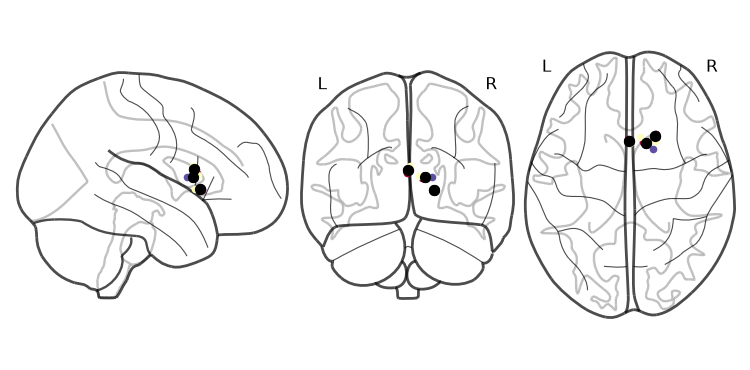

In [7]:
res.plot_nodes()
plt.show()

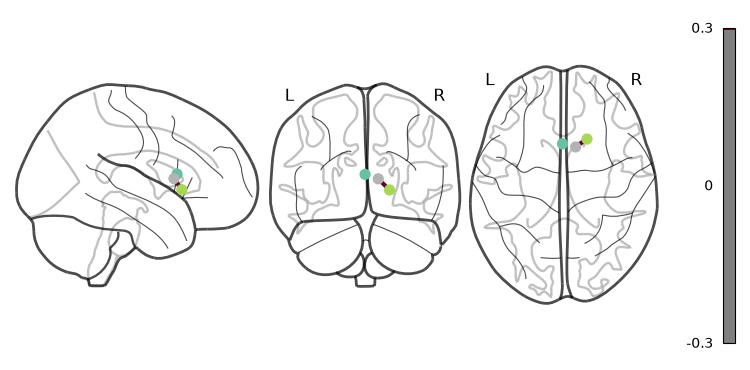

In [8]:
res.plot_connectivity(subject=0)
plt.show()

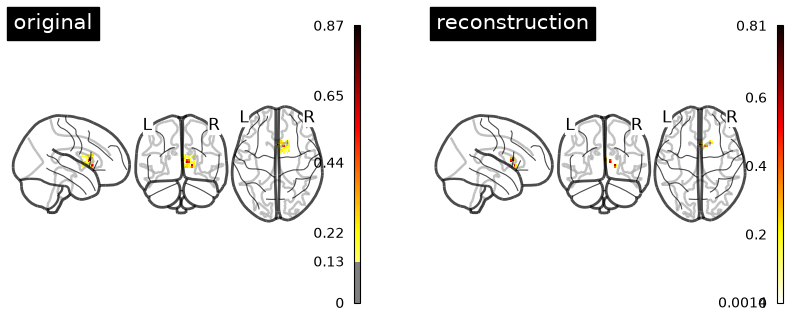

In [9]:
res.plot_reconstruction(subject=0, sample=0)
plt.show()

## Next steps

- `02_tfa_single_subject`: the single-subject estimator and its options.
- `03_htfa_multi_subject`: the hierarchical model, the template and its uncertainty.
- `04_inputs_nifti_folders_nilearn_arrays`: every input type accepted by `htfa.load`.
- The example gallery shows `isfc`, dynamic connectivity and brain-network plots one function at a time.

In [10]:
tmp.cleanup()